In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
x = [5.2, 5.3, 5.4, 5.1, 10.1, 10.3, 9.9, 10.3, 3.2, 3.4, 3.3, 3.1]

In [22]:
def plot_x(data: tuple):
    fig,ax = plt.subplots()
    for i, x in enumerate(data):
        ax.plot(x, marker='o', label=f"data {i}")

    ax.legend()
    # ax.set_xlim(0,11)
    # ax.set_ylim(0, 12)

In [4]:
def conv_3_1_1_zp(x_in, omega):
    x_out = np.zeros_like(x_in)

    size = 3
    stride = 1
    dilation = 1

    padding = len(x_in) % size
    new_in = [0]  + x_in + [0] 

    for i in range(len(x_out)):
        x_out[i] = np.dot(new_in[i : i+size], omega)

    print(x_in, len(x_in))
    print(x_out, len(x_out))
    return x_out

In [5]:
omega = [0.33,0.33,0.33]
h = conv_3_1_1_zp(x, omega)

[5.2, 5.3, 5.4, 5.1, 10.1, 10.3, 9.9, 10.3, 3.2, 3.4, 3.3, 3.1] 12
[ 3.465  5.247  5.214  6.798  8.415  9.999 10.065  7.722  5.577  3.267
  3.234  2.112] 12


In [6]:
omega = [-0.5,0,0.5]
h2 = conv_3_1_1_zp(x, omega)

[5.2, 5.3, 5.4, 5.1, 10.1, 10.3, 9.9, 10.3, 3.2, 3.4, 3.3, 3.1] 12
[ 2.65  0.1  -0.1   2.35  2.6  -0.1   0.   -3.35 -3.45  0.05 -0.15 -1.65] 12


In [7]:
omega = [0.5,0,-0.5]
h2_1 = conv_3_1_1_zp(x, omega)

[5.2, 5.3, 5.4, 5.1, 10.1, 10.3, 9.9, 10.3, 3.2, 3.4, 3.3, 3.1] 12
[-2.65 -0.1   0.1  -2.35 -2.6   0.1   0.    3.35  3.45 -0.05  0.15  1.65] 12


In [8]:
def conv_3_2_1_zp(x_in, omega):

    size = 3
    stride = 2
    dilation = 1

    x_out = np.zeros(int(np.ceil(len(x_in)/stride)))
    padding = len(x_in) % size
    new_in = [0]  + x_in + [0] 

    for i in range(len(x_out)):
        x_out[i] = np.dot(new_in[i*stride : (i*stride)+size], omega)

    return x_out

In [9]:
omega = [0.5,0,-0.5]
h3 = conv_3_2_1_zp(x, omega)

In [11]:
def conv_5_1_1_zp(x_in, omega):

    size = 5
    stride = 1
    dilation = 1

    x_out = np.zeros(int(np.ceil(len(x_in)/stride)))
    
    padding = size // 2
    new_in = [0] * padding  + x_in + [0] * padding

    for i in range(len(x_out)):
        x_out[i] = np.dot(new_in[i*stride : (i*stride)+size], omega)

    return x_out

In [12]:
omega2 = [0.2, 0.2, 0.2, 0.2, 0.2]
h4 = conv_5_1_1_zp(x, omega2)

In [26]:
def conv_zp(x_in, omega, stride, dilation):

    size = len(omega)

    new_omega =[]

    for i in range(size-1):
        new_omega += [omega[i]] + [0] * (dilation - 1)
    new_omega += [omega[-1]]
    new_size = len(new_omega)

    x_out = np.zeros(int(np.ceil(len(x_in)/stride)))

    padding = new_size // 2
    new_in = [0] * padding  + x_in + [0] * padding

    for i in range(len(x_out)):
        x_out[i] = np.dot(new_in[i*stride : (i*stride)+new_size], new_omega)
        # h_i = a * (x_out[i] + beta_i)

    return x_out

In [27]:
omega = [0.33,0.33,0.33]
h5 = conv_zp(x, omega, 1, 2)

[]

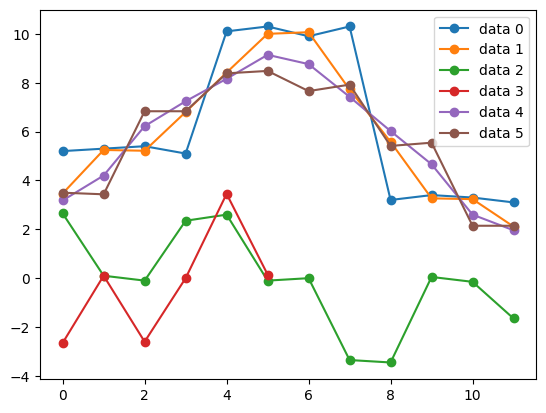

In [28]:
# value of h4 and h5 are close
# but h4 is size 5 and h5 size 3 dilation 2 for kernel
plot_x((x, h, h2, h3, h4, h5))

plt.plot()

In [38]:
def get_conv_mat_3_1_1_zp(n_out, omega):
    omega_mat = np.zeros((n_out,n_out + 2))

    for i in range(omega_mat.shape[0]):
        omega_mat[i, i:i+3] = omega

    return omega_mat[:, 1:-1]

In [39]:
# Run original convolution
omega = np.array([-1.0,0.5,-0.2])
h6 = conv_zp(x, omega, 1, 1)
print(h6)

# If you have done this right, you should get the same answer
omega_mat = get_conv_mat_3_1_1_zp(len(x), omega)
h7 = np.matmul(omega_mat, x)
print(h7)

[ 1.54 -3.63 -3.62 -4.87 -2.11 -6.93 -7.41 -5.39 -9.38 -2.16 -2.37 -1.75]
[ 1.54 -3.63 -3.62 -4.87 -2.11 -6.93 -7.41 -5.39 -9.38 -2.16 -2.37 -1.75]


kernel size: number of elements

stride: step size when move kernel

dilation: space between kernel elements

# what is cnn

The name “Convolutional neural network” indicates that the network employs a mathematical operation called Convolution. 

Convolution is a specialized kind of linear operation. Convnets are simply neural networks that use convolution in place of general matrix multiplication in at least one of their layers.

# what is kernel 

A kernel maps on the input image by simple matrix multiplication and addition, the output obtained is of lower dimensions and therefore easier to work with.

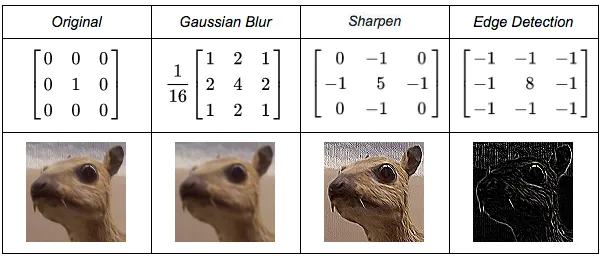

# receptive field

The receptive field of a hidden unit in the network is the region of the original input that
feeds into it

# softmax 

The softmax function is a function that turns a vector of K real values into a vector of K real values that sum to 1. The input values can be positive, negative, zero, or greater than one, but the softmax transforms them into values between 0 and 1, so that they can be interpreted as probabilities.

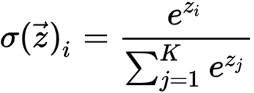



$\sigma$	=	softmax 

$\vec{z}$	=	input vector 

$e^{z_{i}}$	=	standard exponential  function  for  input  vector

$K$	=	number  of  classes  in  the  multi-class  classifier 

$e^{z_{j}}$	=	standard  exponential  function  for  output  vector

$e^{z_{j}}$	=	standard  exponential  function  for  output  vector

$$

1. how the weights were calcualted and kept